# M03 概覽 | observer 的位置由誰決定：標籤與 Quantizer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m03_quantizer_api/00_overview.ipynb)

M02 手插 observer 時，位置是直接照 XNNPACKQuantizer 抄的。真實的後端不能這樣：它要能對**任何**模型自動決定哪裡量化、用什麼規格。
做這件事的就是 **Quantizer**。這一章打開它，最後寫出自己的 Quantizer。
後面七本 notebook（M03-1～M03-7）逐一動手驗證。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m03_quantizer_api")

In [1]:
#| echo: false
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import example_inputs, get_model
from common.pt2e import (
    ANNOTATION_KEY,
    Quantizer,
    annotate_output_qspec,
    export_module,
    get_xnnpack_quantizer,
    prepare_pt2e,
    quiet,
)
from common.qspecs import act_spec
from common.viz import annotation_notes, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## 為什麼需要 Quantizer

同一個 conv，後面接 relu 時要不要在中間量化？add 的兩個輸入要不要用同一個 scale？bias 要不要量化成 int32？
這些都是**後端**的決定：硬體能融合哪些 op、整數加法怎麼做，每個後端不同。PT2E 把這些決定集中在 Quantizer 裡，`prepare_pt2e` 和 `convert_pt2e` 本身不需要知道任何後端。

這一章回答四個問題：

| 問題 | 一句話的答案 | 動手驗證 |
|---|---|---|
| Quantizer 怎麼告訴 `prepare_pt2e` 位置？ | 在 node 上貼標籤；`prepare_pt2e` 照標籤插 observer | M03-1、M03-2 |
| Quantizer 怎麼在任何模型上找到該標的 op？ | 用規則（`node.target`、pattern）找，不點名 | M03-3、M03-6 |
| 不同位置的 qparams 怎麼連動？ | 共用同一個 observer，或由別的位置推導、或寫死 | M03-4、M03-5 |
| 使用者怎麼指定哪一段用什麼規格？ | 後端各自的設定 API，背後就是規則 | M03-6、M03-7 |

## 先看一個例子：XNNPACKQuantizer 在 conv → relu 上做了什麼

第一個階段是 Quantizer 標完的圖，每個 node 底下寫著它的標籤：每條輸入邊一行「邊 上游：規格」，輸出一行「輸出：規格」。
第二個階段是 `prepare_pt2e` 之後的圖，綠框是新長出來的 observer。請看兩件事：

- 每一張標籤都變成一個 observer，位置一一對應。bias 的規格是「不量化」，所以沒有 observer。
- conv2d 的輸出**沒有標籤**，所以 conv 與 relu 之間沒有 observer：XNNPACKQuantizer 把 conv + relu 當成一個 pattern，後端可以融成一個 kernel。

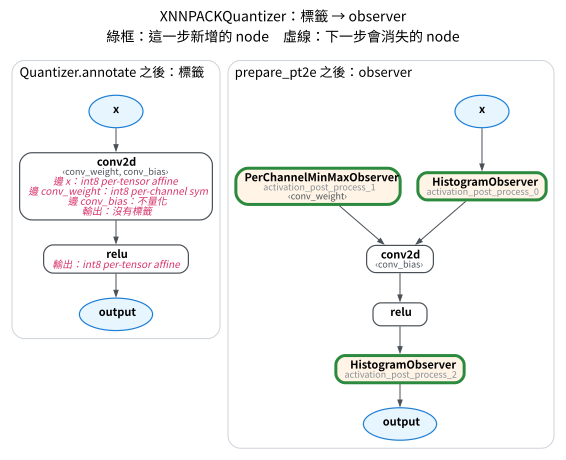

In [2]:
#| echo: false
gm = export_module(get_model("conv_relu").eval(), example_inputs(4))
xnnpack, _ = get_xnnpack_quantizer(is_per_channel=True)
annotated = xnnpack.annotate(copy.deepcopy(gm))  # conv_relu 沒有 BN，Quantizer 看到的就是這張圖
prepared = prepare_pt2e(copy.deepcopy(gm), get_xnnpack_quantizer(is_per_channel=True)[0])
draw_stages([(annotated, "Quantizer.annotate 之後：標籤"), (prepared, "prepare_pt2e 之後：observer")],
            notes=[annotation_notes(annotated), {}], title="XNNPACKQuantizer：標籤 → observer")

## 定義

### 三個角色

| 角色 | 是什麼 | 做什麼 |
|---|---|---|
| 標籤 `QuantizationAnnotation` | 存在 `node.meta["quantization_annotation"]` 的資料 | 記錄這個 node 的哪些輸入邊、或它的輸出要量化，用什麼規格 |
| `Quantizer` | 後端作者寫的類別 | 在圖上找 node、貼標籤、檢查圖能不能處理 |
| `prepare_pt2e` | torchao 的函式 | 呼叫 Quantizer，再照標籤插 observer；沒有標籤的地方什麼都不做 |

### 標籤：兩種位置

`QuantizationAnnotation` 用兩個欄位描述位置：

- `input_qspec_map`：`{上游 node: spec}`，貼在 consumer 上，表示「上游 → 這個 node」這條**邊**要量化。只影響這一個 consumer。
- `output_qspec`：這個 node 的**輸出**要量化。影響輸出的所有 consumer。

另外兩個欄位：`_annotated`（已經處理過，其他 Quantizer 不要再動，M03-3、M03-6）與 `allow_implicit_sharing`（M03-4）。

### 規格：QuantizationSpec

每個位置的規格是一份 `QuantizationSpec`，回答「量化成什麼樣子、用哪種 observer 收集統計」。
上面例子裡 XNNPACKQuantizer 的 activation 與 weight 規格：

In [3]:
cfg = xnnpack.global_config
assert cfg is not None and cfg.input_activation is not None and cfg.weight is not None
rows = []
for field in ("dtype", "quant_min", "quant_max", "qscheme", "ch_axis", "observer_or_fake_quant_ctr"):
    values = []
    for spec in (cfg.input_activation, cfg.weight):
        v = getattr(spec, field)
        v = getattr(getattr(v, "p", None), "func", v)  # with_args 包過的 observer，剝開取類別
        values.append(getattr(v, "__name__", str(v)))
    rows.append([field, *values])
table(rows, ["欄位", "activation", "weight"])

欄位,activation,weight
dtype,torch.int8,torch.int8
quant_min,-128,-127
quant_max,127,127
qscheme,torch.per_tensor_affine,torch.per_channel_symmetric
ch_axis,None,0
observer_or_fake_quant_ctr,HistogramObserver,PerChannelMinMaxObserver


activation 是 int8 per-tensor affine，weight 是 int8 per-channel symmetric、沿 output channel（`ch_axis=0`）各一個 scale。
用哪種 observer 是這份 XNNPACKQuantizer 預設設定的選擇（M02-1 比較過各種 observer）。

除了一般的 `QuantizationSpec`，還有三種 spec，差在 qparams 從哪來：

| spec | qparams 從哪來 | 例子 | notebook |
|---|---|---|---|
| `QuantizationSpec` | 自己的 observer 看資料算 | 大部分的 activation、weight | M03-1 |
| `SharedQuantizationSpec(位置)` | 和另一個位置共用同一個 observer | add、cat 的輸入與輸出用同一個 scale | M03-4 |
| `DerivedQuantizationSpec` | 由其他位置的 observer 推導 | int32 bias：scale = activation scale × weight scale | M03-5 |
| `FixedQParamsQuantizationSpec` | 寫死在 spec 裡 | sigmoid 的輸出（值域已知）；交給定點 DSP 的模型輸出（格式已規定） | M03-5 |

`FixedQParamsQuantizationSpec` 的兩種用途，共通點是 qparams 事先就知道，不必從資料估。
第二種的例子：speech enhancement 模型輸出的 spectrogram 要直接交給用定點數運算的 DSP，雙方約定格式是 Q3.12（int16、scale $2^{-12}$），
scale 就得照約定寫死，不能交給校準決定。

### Quantizer 的三個方法與 prepare_pt2e 的順序

| 方法 | 必須實作？ | 做什麼 |
|---|---|---|
| `transform_for_annotation(model)` | 否（基底預設不改圖） | 標註前改寫圖，例如把純量常數變成 tensor 屬性 |
| `annotate(model)` | 是 | 找 node、貼標籤 |
| `validate(model)` | 是 | 標完之後檢查這張圖能不能處理，不行就報錯 |

`prepare_pt2e` 依序（torchao 0.18）：把 BN 折進 conv → `transform_for_annotation` → `annotate` → `validate` → 照標籤插 observer。
所以 Quantizer 看到的是 BN 已經折掉的圖（M03-1 B 段驗證過呼叫順序，M03-2 用這件事拿到標完的圖）。

QAT 用的 `prepare_qat_pt2e` 順序不同：`transform_for_annotation` → `annotate` → `validate` 之後才處理 conv + BN（`_fuse_conv_bn_qat`），而且 BN 不折掉，留在圖上繼續訓練。
所以 QAT 時 Quantizer 看到的是 BN **沒有**折掉的圖（QAT 圖上的 BN 長什麼樣，見 M04-2）。

### 找 node 的兩種方式

- **點名**：用 node 名稱，例如「`relu` 的輸出」。換了模型就失效，只適合實驗（M03-1、M03-4 B 段）。
- **規則**：用 `node.target` 比對 op，必要時看前後文（例如 conv 的唯一使用者是 relu）。模型換了照樣適用，真實的 Quantizer 都這樣做（M03-3）。

torchao 測試版 XNNPACKQuantizer 有些 annotator 依賴 `node.meta["source_fn_stack"]` 找 pattern，torch 2.14 的 export 不再填這個欄位，`cat` 因此靜默沒被標（M03-2 C 段）。

## 用程式驗證：十行的規則式 Quantizer

只標所有 relu 的輸出。`annotate_output_qspec` 是 torchao 提供的公開輔助函式，會在需要時建立標籤：

In [4]:
class ReluOutputQuantizer(Quantizer):
    def annotate(self, model):
        for node in model.graph.nodes:
            if node.op == "call_function" and node.target == torch.ops.aten.relu.default:
                annotate_output_qspec(node, act_spec())
                node.meta[ANNOTATION_KEY]._annotated = True
        return model

    def validate(self, model):
        pass


for name in ("conv_relu", "residual", "tiny"):
    p = prepare_pt2e(export_module(get_model(name).eval(), example_inputs(4)), ReluOutputQuantizer())
    n_relu = sum(n.target == torch.ops.aten.relu.default for n in p.graph.nodes)
    print(f"{name:<10} relu {n_relu} 個 → observer {len(observer_nodes(p))} 個")
    assert len(observer_nodes(p)) == n_relu

conv_relu  relu 1 個 → observer 1 個
residual   relu 2 個 → observer 2 個
tiny       relu 4 個 → observer 4 個


同一個 Quantizer 不需要知道模型長什麼樣，三個模型上 observer 數都等於 relu 數。

## 小結與本章地圖

- `prepare_pt2e` 自己不知道哪裡該量化，它只照標籤插 observer；位置與規格全部由 Quantizer 決定。
- 標籤有兩種位置（輸入邊、輸出）；規格有四種 spec，差在 qparams 從哪來。
- Quantizer 用規則找 node；fusion、共用、局部量化，都只是「標籤怎麼貼」的不同寫法。

| notebook | 回答的問題 |
|---|---|
| [M03-1 標籤與 prepare_pt2e](01_annotate_then_prepare.ipynb) | 標籤長什麼樣、三個角色怎麼分工、邊標籤與輸出標籤 |
| [M03-2 讀懂 XNNPACKQuantizer 的標籤](02_read_annotations.ipynb) | 真實的 Quantizer 貼了什麼、fusion 在標籤上的樣子、哪些 op 沒被標到 |
| [M03-3 規則式 Quantizer](03_my_first_quantizer.ipynb) | 用 `node.target` 找 op、`_annotated`、`validate` |
| [M03-4 共用 qparams](04_shared_and_implicit_sharing.ipynb) | `SharedQuantizationSpec`、隱式共用何時合併、何時串接 |
| [M03-5 Derived 與 FixedQParams](05_derived_and_fixed_qparams.ipynb) | int32 bias 的 scale 怎麼推導；值域已知、或輸出格式已規定（例如 Q3.12）時用固定 qparams |
| [M03-6 局部量化與組合](06_partial_quantization.ipynb) | 只量化一部分、`ComposableQuantizer`、標註順序 |
| [M03-7 後端的設定 API](07_backend_config_api.ipynb) | `X86InductorQuantizer` 的優先順序、XNNPACKQuantizer 默默不生效的設定 |

這一章刻意跳過的：BN 怎麼折進 conv、QAT 圖上的 fusion（M04）；哪些層該留在 fp32（M05）；為一個虛構的硬體從頭寫完整的 Quantizer（M10）。

## 參考資料

- torchao 0.18 原始碼：
  [`quantizer/quantizer.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantizer/quantizer.py)（標籤與四種 spec）、
  [`prepare.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/prepare.py)（照標籤插 observer、隱式共用）、
  [`quantizer/composable_quantizer.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantizer/composable_quantizer.py)、
  [`quantizer/x86_inductor_quantizer.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/quantizer/x86_inductor_quantizer.py)
- PyTorch 官方教學：[How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- [PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)：`node.target`、`node.meta`、`users` 等基本概念